# Análisis exploratorio de datos para finanzas

En esta sesión vamos a aplicar el **análisis de datos exploratorio** para responder a preguntas:

* ¿Qué **rentabilidad media** ha obtenido un activo?
* ¿Qué **volatilidad** tiene?
* ¿Cómo se **distribuyen** sus retornos?
* ¿Existen **valores atípicos**?
* ¿Cómo se **relacionan** los retornos de dos activos?
* ¿Cómo visualizo **series temporales**?
* ¿Qué información podemos extraer antes de construir un modelo financiero?

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Datos

### Variables que analizaremos

- **Precio de cierre (*Close*):** precio al que termina la sesión bursátil. Nos permite estudiar la evolución del valor de un activo a lo largo del tiempo.

- **Retornos (*Returns*):** variación porcentual del precio entre dos sesiones consecutivas. Miden cuánto ha ganado o perdido un activo en un periodo determinado.
$$R_t = \frac{P_t-P_{t-1}}{P_{t-1}}$$
Son especialmente interesantes en finanzas porque permiten **medir y comparar la rentabilidad de distintos activos**, independientemente de sus precios, y analizar su **riesgo y volatilidad**.

### Importación de datos

#### A partir de archivo

In [2]:
# Datos de retornos de un activo financiero
df = pd.read_csv("retornos.csv")

In [4]:
df.head(2)

,Retornos
0,0.000000
1,0.400157


#### yfinance (Yahoo)

In [19]:
import yfinance as yf

In [18]:
yf.download('GOOG', start = '2025-01-01', end = '2025-01-10')

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,GOOG,GOOG,GOOG,GOOG,GOOG
Date,,,,,
2025-01-02,189.519882,192.074908,187.611065,190.369899,17545200
2025-01-03,192.005325,193.367342,190.235692,191.602685,12875000
2025-01-06,196.807220,198.397894,193.924099,194.013571,19483300
2025-01-07,195.564484,200.962855,194.798963,197.115397,16966800
2025-01-08,194.252182,196.489080,192.621733,192.820565,14335300


## Descripción Univariada

### Estadísticos descriptivos

* ¿Cuál es el **retorno medio** del activo?
* ¿Qué **volatilidad** tiene?

In [7]:
df.describe()

,Retornos
count,100.000000
mean,0.098134
std,1.561397
min,-3.143049
25%,-1.220633
50%,0.029405
75%,1.472889
max,4.053019


* ¿Cómo podemos calcular **percentiles**?

In [8]:
# Cálculo de percentiles
df.quantile(0.05)

Retornos   -2.043146
Name: 0.05, dtype: float64

In [9]:
df.sort_values(by='Retornos')

,Retornos
42,-3.143049
63,-2.889106
66,-2.815469
20,-2.463650
41,-2.052541
...,...
16,2.516339
97,2.708873
86,2.760803
3,3.122087


### Histograma

Para entender la forma de la distribución, se utilizan histogramas y gráficos de densidad. Estos permiten identificar asimetrías y posibles modas.

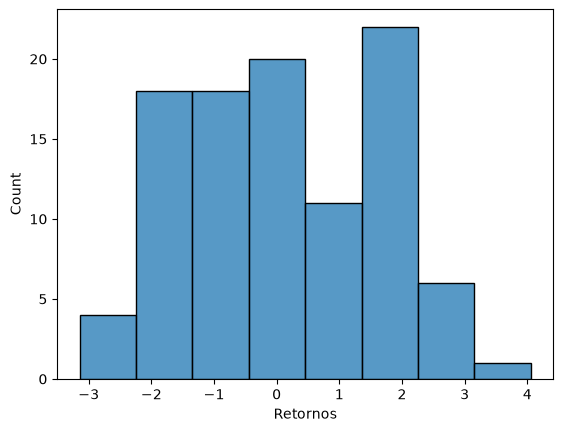

In [10]:
# Frecuencias absolutas de 'Retornos'
sns.histplot(data = df, x="Retornos")
plt.show()

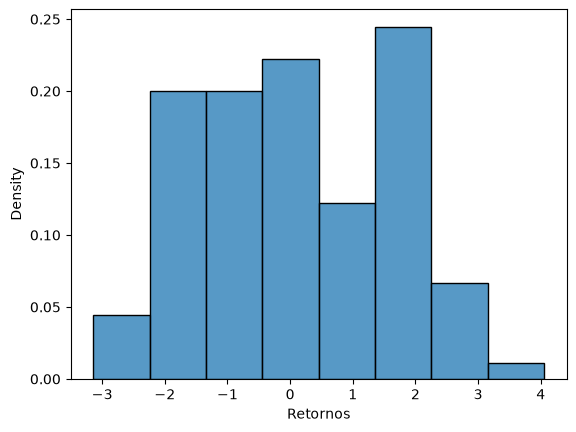

In [11]:
# Frecuencias relativas de 'Retornos'
sns.histplot(data = df, x="Retornos", stat='density')
plt.show()

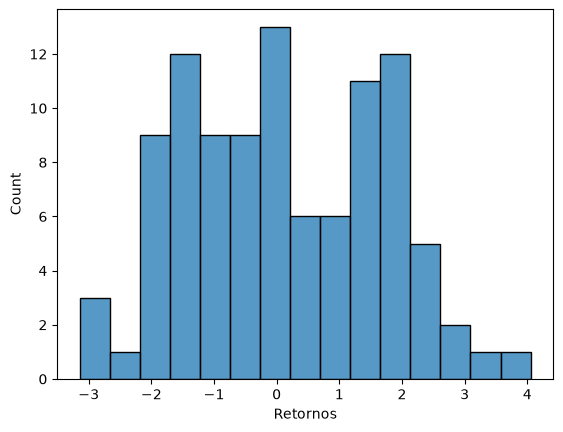

In [12]:
# Jugando con los 'bins'
sns.histplot(data = df, x="Retornos", bins=15)
plt.show()

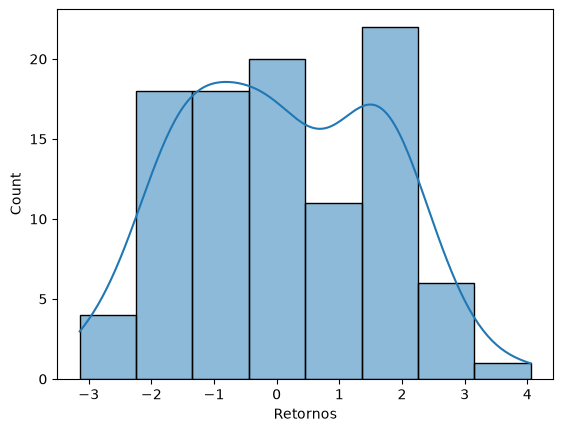

In [13]:
# Sobreponiendo la densidad
sns.histplot(data = df, x="Retornos", kde=True)
plt.show()

### Violín

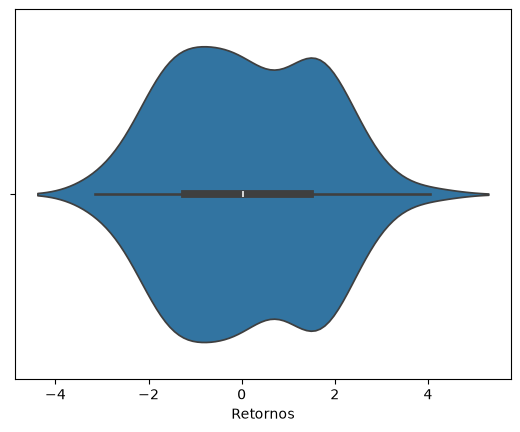

In [14]:
# Gráfico de Violín (Violin plot) - Muestra la densidad de la distribución
sns.violinplot(data = df, x='Retornos')
plt.show()

### Jitterplot

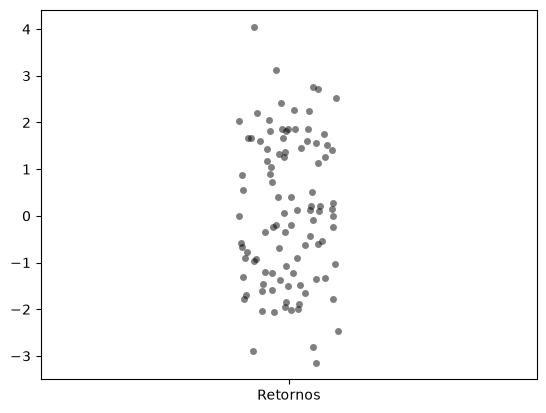

In [15]:
sns.stripplot(data=df, color='black', alpha=0.5, jitter=True)
plt.show()

### Boxplot

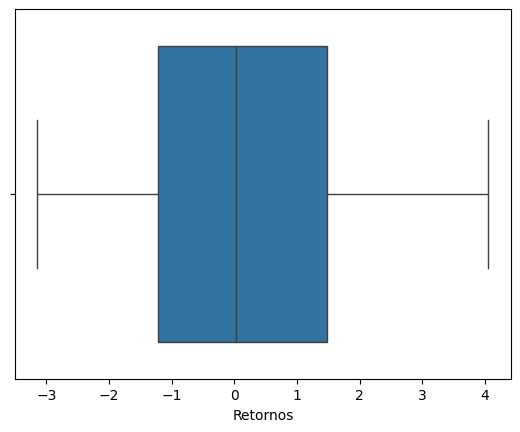

In [ ]:
sns.boxplot(data = df, x="Retornos")
plt.show()

In [16]:
df.describe()

,Retornos
count,100.000000
mean,0.098134
std,1.561397
min,-3.143049
25%,-1.220633
50%,0.029405
75%,1.472889
max,4.053019


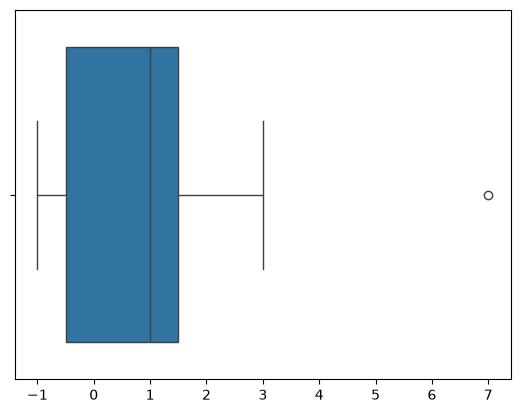

In [17]:
# Outlier (por encima)
sns.boxplot(x=[-1,-1,-1,0,0,1,1,1,2,3,7])
plt.show()

In [17]:
# Outlier (por debajo)
sns.boxplot(x=[-6,-5,-2, -1,-1,-1,0,0,1,1,1,2,3])
plt.show()

NameError: name 'sns' is not defined

✅ **Boxplot recap**
* https://www.khanacademy.org/math/statistics-probability/summarizing-quantitative-data/box-whisker-plots/a/box-plot-review

* Identifying outliers in box whisker plots:

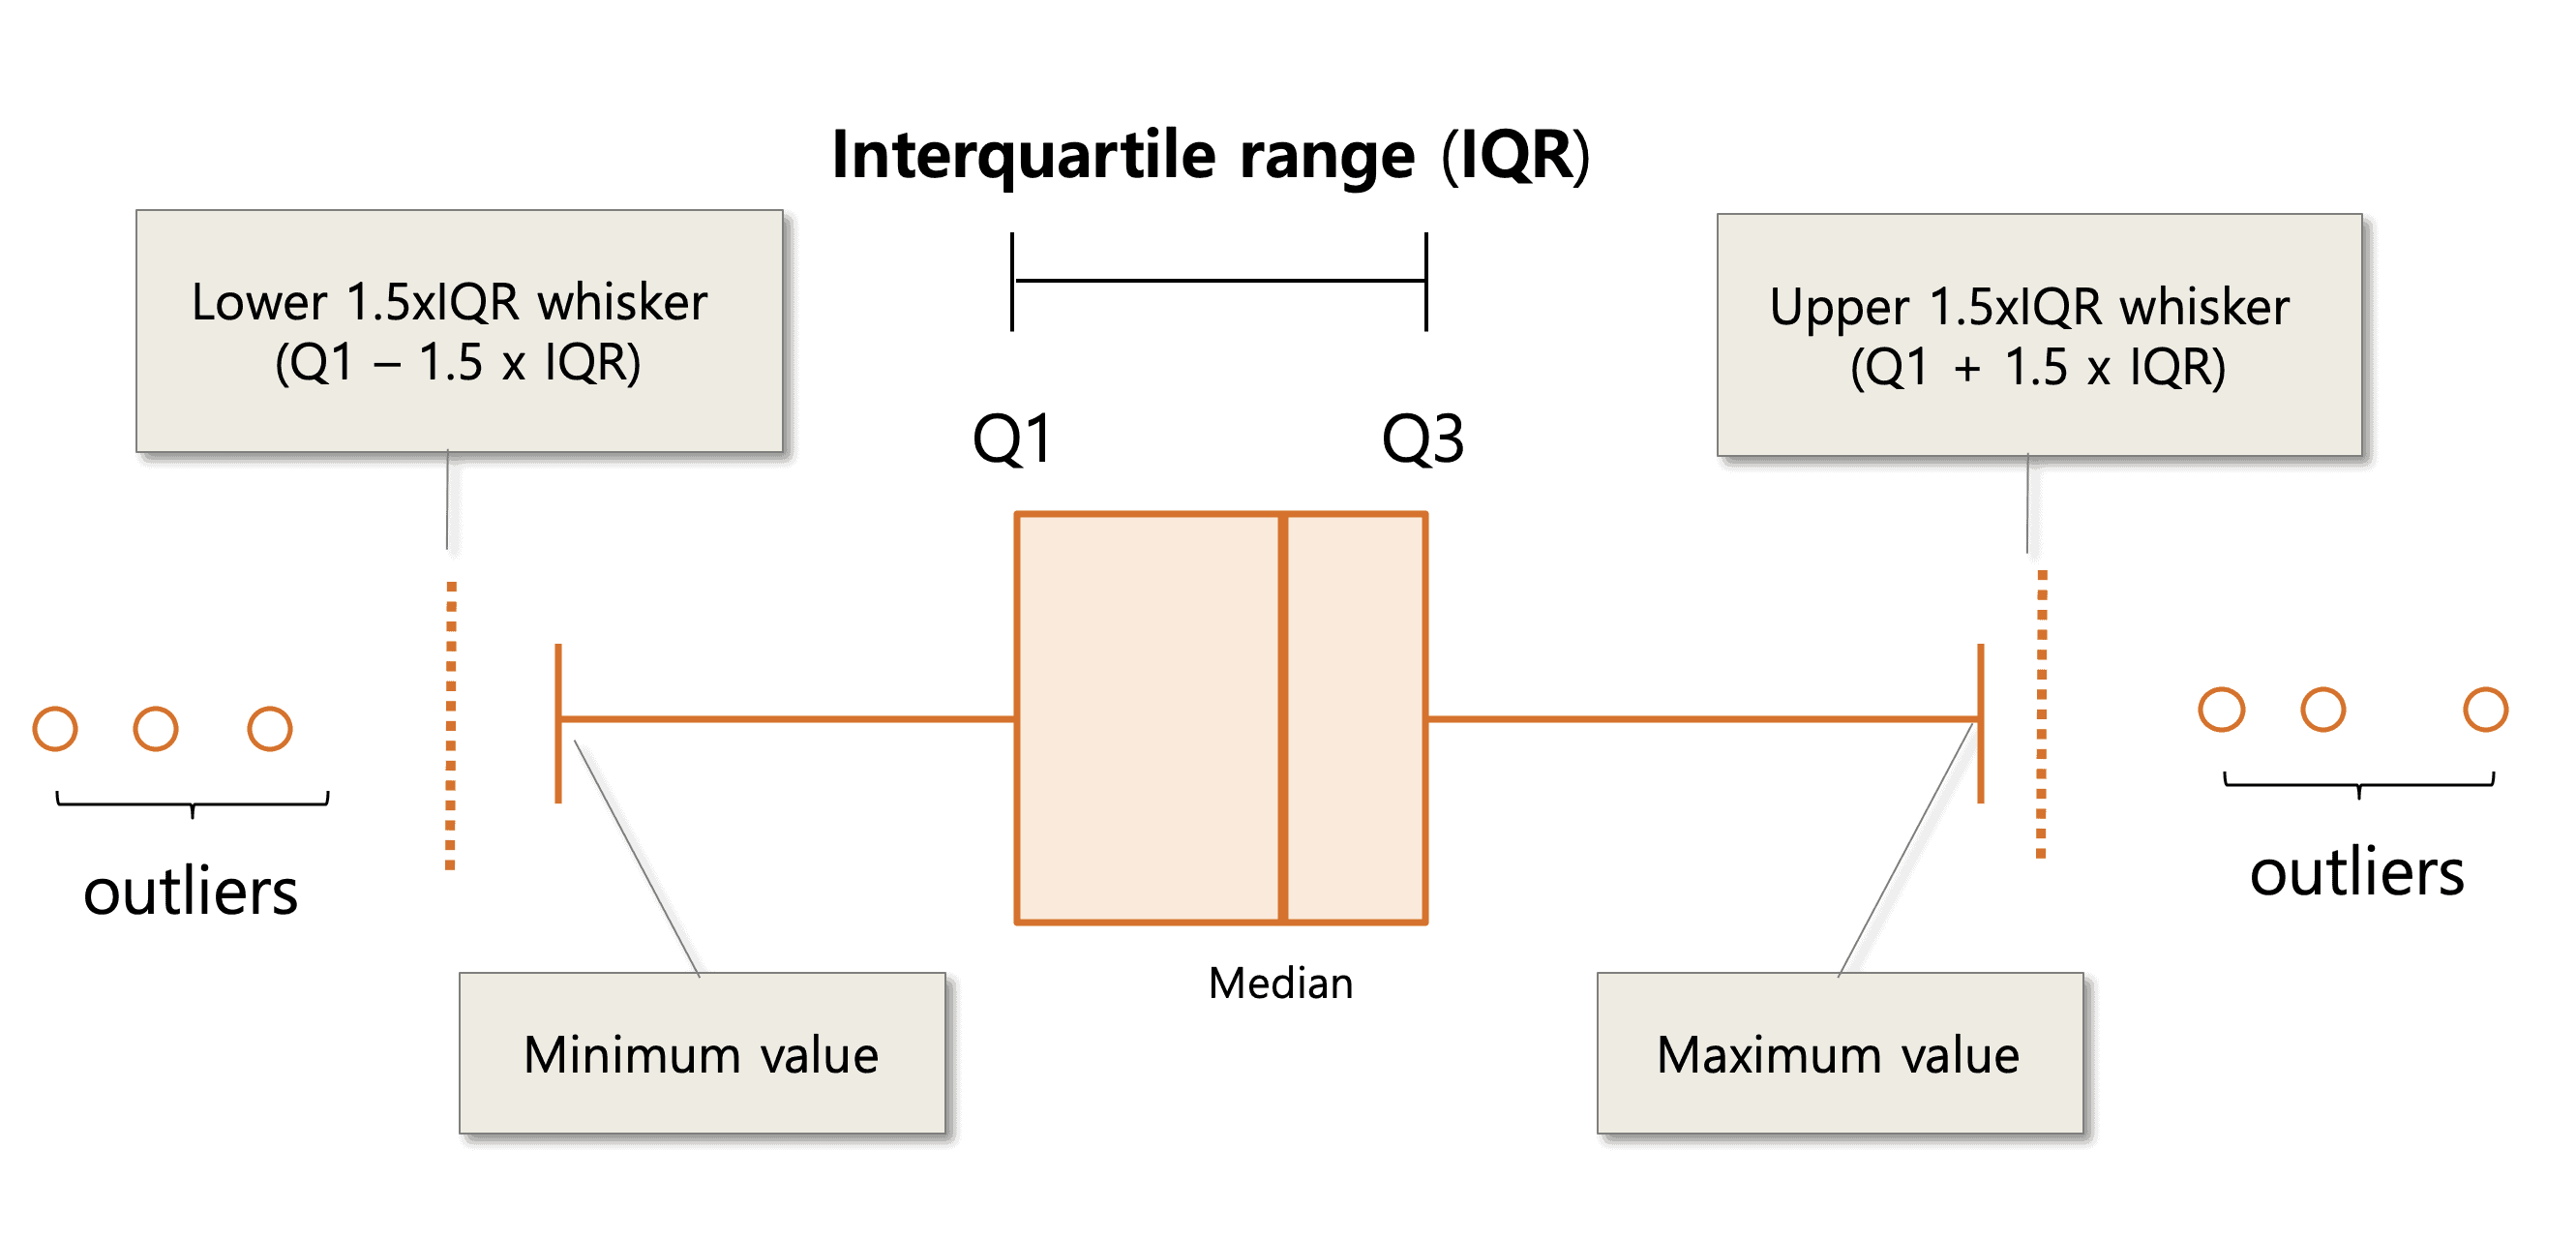

### 🧩 Ejercicio 1

Usa el paquete *yfinance* para importar datos de los precios de cierre de Google a lo largo de 2023 y estudia su distribución:

* ¿Cuál es el precio medio?
* ¿Cuál es la desviación estándard?
* Histograma y boxplot
* ¿Los precios se distribuyen de forma simétrica?
* ¿Existen valores atípicos?

In [13]:
# Precio de cierre de Google

import yfinance as yf
precios = yf.download('GOOG', start='2023-01-01', end = '2023-12-31')['Close']

[*********************100%***********************]  1 of 1 completed


In [12]:
precios

Ticker,GOOG
Date,
2023-01-03,88.858360
2023-01-04,87.877640
2023-01-05,85.955856
2023-01-06,87.332817
2023-01-09,87.966812
...,...
2023-12-22,141.380920
2023-12-26,141.479950
2023-12-27,140.112885


In [14]:
# Precio medio y desviación estándard
precios.describe()

Ticker,GOOG
count,250.000000
mean,118.489569
std,16.219643
min,85.955856
25%,104.155970
50%,122.801876
75%,132.039375
max,141.479950


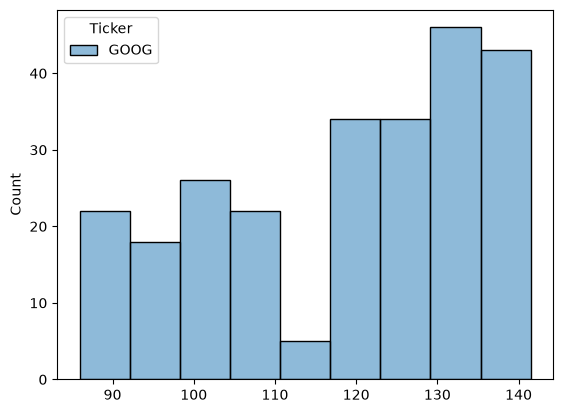

In [21]:
# Histograma
sns.histplot(data = precios)
plt.show()

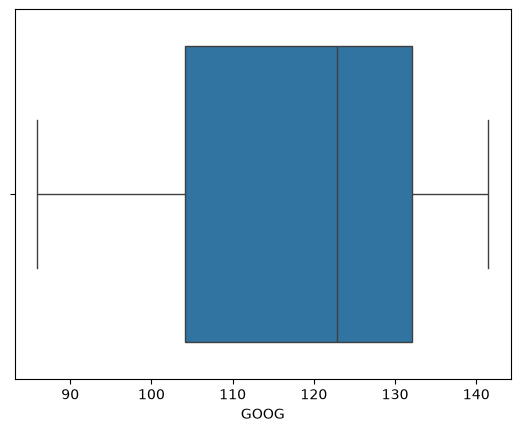

In [22]:
# Boxplot
sns.boxplot(data = precios, x = 'GOOG')
plt.show()

## Comparando Distribuciones

* Es muy habitual que queramos comparar la distribución de los valores de dos variables.
* Por ejemplo: *¿cómo se distibuyen los retornos de Google y Apple entre 2023 y 2025?*

In [23]:
# Retornos de Google y Apple
data = yf.download(['GOOG', 'AAPL'], start = '2023-01-01', end = '2025-12-31')['Close']
returns = data.pct_change()  #cambia los precios a los retornos
returns

[*********************100%***********************]  2 of 2 completed


Ticker,AAPL,GOOG
Date,,
2023-01-03,NaN,NaN
2023-01-04,0.010314,-0.011037
2023-01-05,-0.010605,-0.021869
2023-01-06,0.036794,0.016020
2023-01-09,0.004089,0.007259
...,...,...
2025-12-23,0.005130,0.013972
2025-12-24,0.005324,-0.000032
2025-12-26,-0.001497,-0.002249


In [24]:
# Estadísticos descriptivos
returns.describe()

Ticker,AAPL,GOOG
count,750.000000,750.000000
mean,0.001191,0.001864
std,0.016137,0.018966
min,-0.092456,-0.095989
25%,-0.006654,-0.008789
50%,0.001400,0.002477
75%,0.008725,0.011729
max,0.153289,0.099652


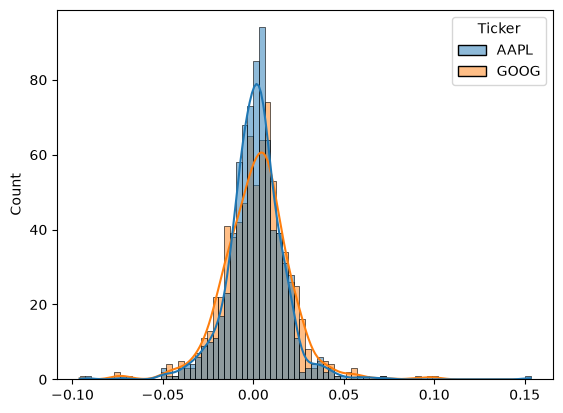

In [25]:
# Histogramas
sns.histplot(data = returns, kde = True)
plt.show()

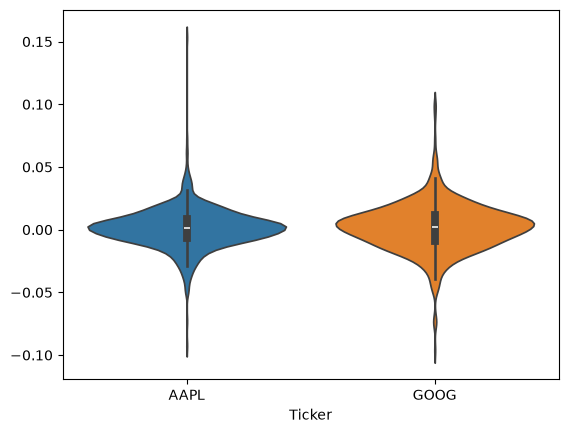

In [26]:
# Gráfico de Violín (Violin plot) - Muestra la densidad de la distribución
sns.violinplot(data=returns)
plt.show()

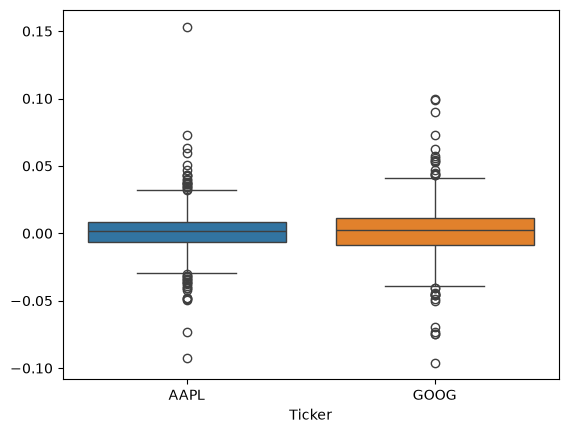

In [27]:
# Boxplots
sns.boxplot(data=returns)
plt.show()

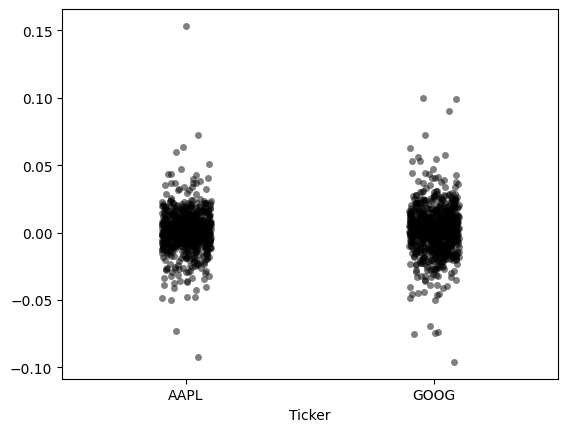

In [ ]:
# Gráfico de Dispersión/Puntos (Jitter/Strip Plot) - Muestra los datos brutos [3]
sns.stripplot(data=returns, color='black', alpha=0.5, jitter=True)
plt.show()

### 🧩 Ejercicio 2

Importa datos de los retornos de Apple (acción americana) y S&P 500 (índice de referencia) y compara sus distribuciones:

* ¿Quién tiene un mayor retorno medio?
* ¿Quién tiene mayor volatilidad (desviación estándard)?
* Compara las dos distribuciones (hitograma/boxplot).
* ¿Existen valores atípicos para algunos de los retornos?
* Para cada uno de los dos activos, completa la frase: *"el 5% de los días voy a perder más del ___ %"*

Datos:

```
data = yf.download(['AAPL', '^GSPC'], start = '2025-01-01', end = '2025-12-31')['Close']
returns = data.pct_change()
```



In [28]:
# Importar datos
data = yf.download(['AAPL', '^GSPC'], start = '2025-01-01', end = '2025-12-31')['Close']
returns = data.pct_change()

[*********************100%***********************]  2 of 2 completed


In [30]:
returns.dropna()

Ticker,AAPL,^GSPC
Date,,
2025-01-03,-0.002009,0.012596
2025-01-06,0.006739,0.005538
2025-01-07,-0.011388,-0.011104
2025-01-08,0.002023,0.001560
2025-01-10,-0.024104,-0.015412
...,...,...
2025-12-23,0.005130,0.004550
2025-12-24,0.005324,0.003221
2025-12-26,-0.001497,-0.000304


In [31]:
# Media y volatilidad
returns.describe()

Ticker,AAPL,^GSPC
count,248.000000,248.000000
mean,0.000681,0.000720
std,0.020489,0.011848
min,-0.092456,-0.059750
25%,-0.006729,-0.003543
50%,0.000790,0.001363
75%,0.006617,0.005800
max,0.153289,0.095154


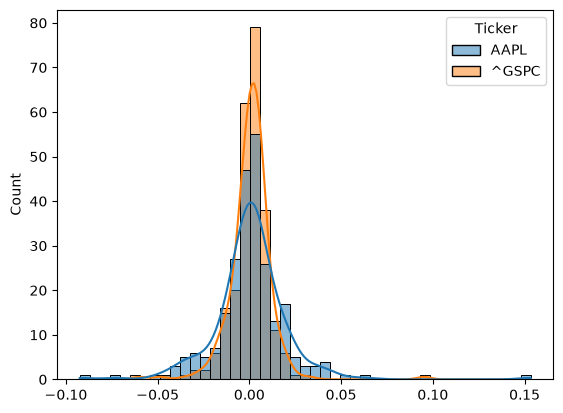

In [32]:
# Distribución de los retornos
sns.histplot(data = returns, kde = True)
plt.show()

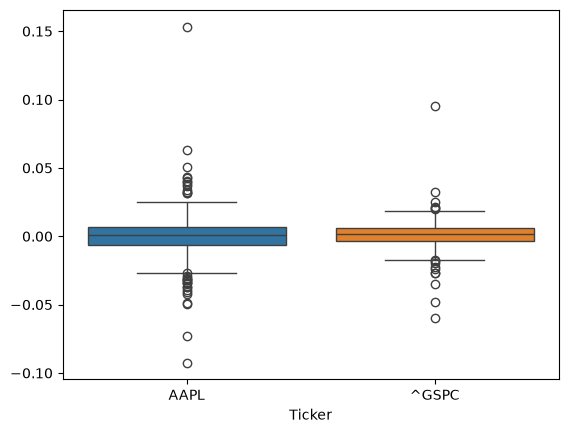

In [33]:
# Distribución de los retornos
sns.boxplot(data = returns)
plt.show()

In [34]:
# Percentil 5%
returns.quantile(0.05)

Ticker
AAPL    -0.032139
^GSPC   -0.016085
Name: 0.05, dtype: float64

##  Descripción Bivariada

* Para explorar la relación entre dos variables cuantitativas, el gráfico de dispersión (scatterplot) es la herramienta fundamental.
* *Veamos como se relacionan los retornos de Apple y S&P 500 en el 2025.*

In [35]:
# Retornos de Apple y S&P 500 en el 2025.
data = yf.download(['AAPL', '^GSPC'], start = '2025-01-01', end = '2025-12-31')['Close']
returns = data.pct_change()

[*********************100%***********************]  2 of 2 completed


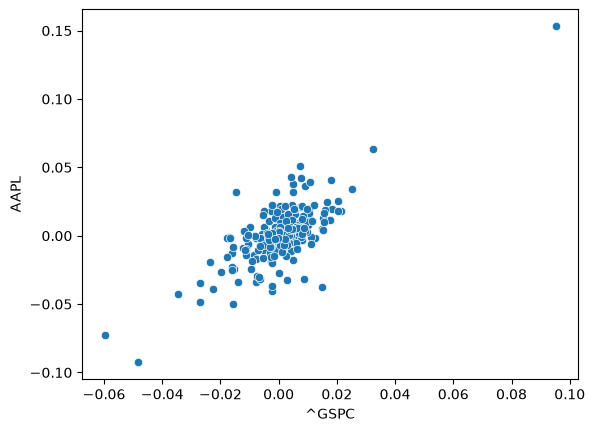

In [36]:
# Gráfico de dispersión
sns.scatterplot(data=returns, x='^GSPC', y='AAPL')
plt.show()

El gráfico de dispersión ayuda a determinar si existe una relación (e.g., lineal) entre las variables.

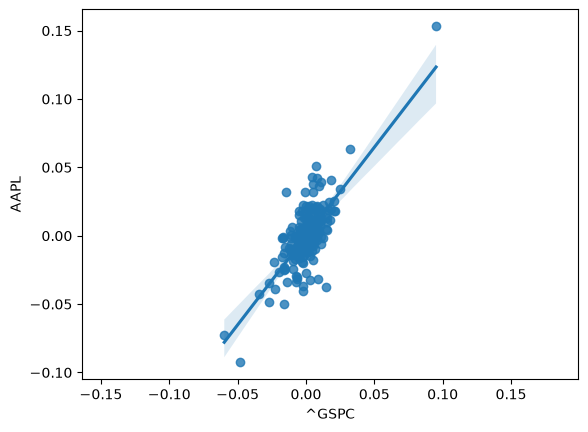

In [37]:
# Gráfico de dispersión
sns.regplot(data=returns, x='^GSPC', y='AAPL')
plt.axis('equal')
plt.show()

## Otras visualizaciones

### Pairplot

* Si queremos visualizar relaciones de **múltiples variables cuantitativas** dos a dos.
* Por ejemplo, *¿cómo se relacionan los retornos de Apple, Tesla y S&P 500?*

In [38]:
data = yf.download(['AAPL', 'TSLA', '^GSPC'], start = '2025-01-01', end = '2025-12-31')['Close']
returns = data.pct_change()

[*********************100%***********************]  3 of 3 completed


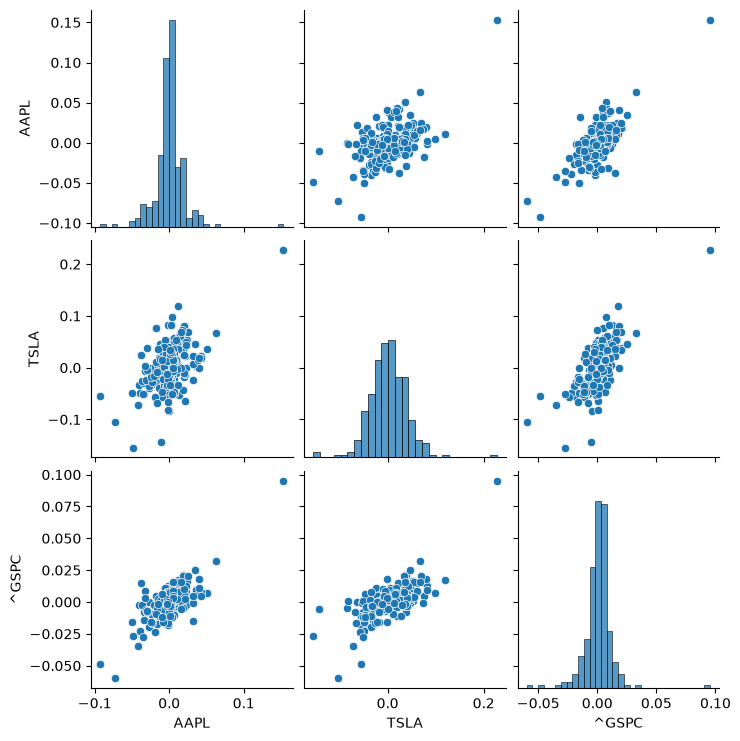

In [39]:
# Pairplot
sns.pairplot(data = returns)
plt.show()

### Heatmap de correlaciones

* La **correlación** es una medida de la asociación lineal entre variables.
* Un **heatmap** es una visualización óptima para la correlación entre múltiples varaibles.

In [40]:
corr = returns.corr()
corr

Ticker,AAPL,TSLA,^GSPC
Ticker,,,
AAPL,1.000000,0.525195,0.751375
TSLA,0.525195,1.000000,0.693553
^GSPC,0.751375,0.693553,1.000000


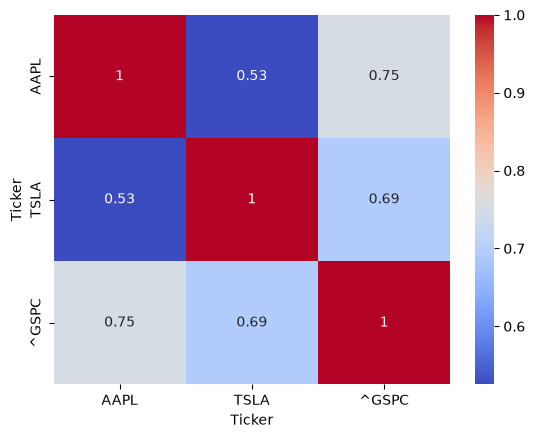

In [41]:
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

### Series temporales

* La **visualización de series temporales** es una herramienta fundamental en finanzas.

In [42]:
data

Ticker,AAPL,TSLA,^GSPC
Date,,,
2025-01-02,242.093140,379.279999,5868.549805
2025-01-03,241.606659,410.440002,5942.470215
2025-01-06,243.234848,411.049988,5975.379883
2025-01-07,240.464951,394.359985,5909.029785
2025-01-08,240.951401,394.940002,5918.250000
...,...,...,...
2025-12-23,271.620667,485.559998,6909.790039
2025-12-24,273.066711,485.399994,6932.049805
2025-12-26,272.657837,475.190002,6929.939941


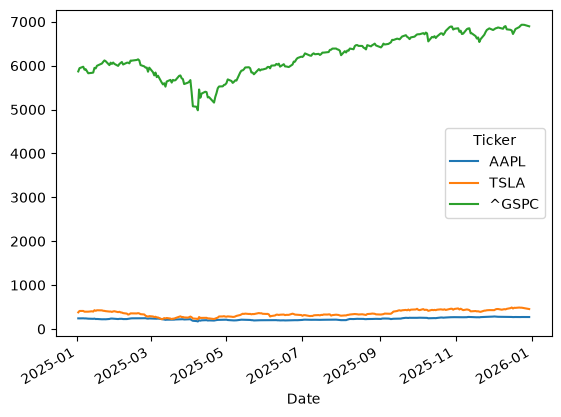

In [43]:
# Evolución de los precios
data.plot()
plt.show()

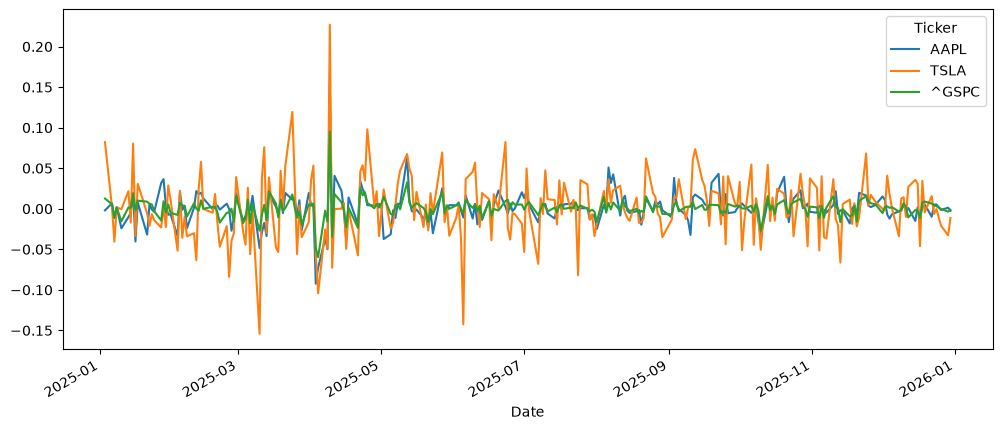

In [44]:
# Evolución de los retornos
returns.plot(figsize=(12, 5))
plt.show()

## 🧩 Ejercicio Final

Un inversor quiere comparar retornos de tres activos Apple, Nvidia y Coca-Cola antes de construir una cartera de inversión.

1. ¿Qué activo tiene mayor retorno medio diario?
2. ¿Cuál tiene mayor volatilidad?
3. ¿Los retornos son aproximadamente normales en los tres casos?
4. ¿Qué activo presenta menos valores atípicos?
5. ¿Qué activos están más correlacionados?
6. ¿Qué activo elegirías si priorizaras minimizar el riesgo?

Instrucciones:
* Usa datos del 2025.
* Usa el precio de cierre para el cálculo de retornos.
* Los tickers son AAPL, NVDA y KO.

In [45]:
import yfinance as yf

tickers = ['AAPL', 'NVDA', 'KO']

prices = yf.download(
    tickers,
    start='2025-01-01',
    end='2025-12-31'
)['Close']

returns = prices.pct_change().dropna()

[*********************100%***********************]  3 of 3 completed


In [46]:
returns.describe()

Ticker,AAPL,KO,NVDA
count,248.000000,248.000000,248.000000
mean,0.000681,0.000682,0.001721
std,0.020489,0.011067,0.031328
min,-0.092456,-0.044411,-0.169682
25%,-0.006729,-0.006402,-0.011636
50%,0.000790,0.000070,0.002658
75%,0.006617,0.006997,0.018402
max,0.153289,0.047250,0.187227


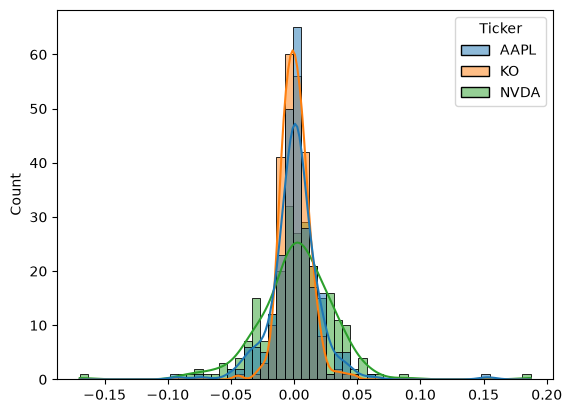

In [47]:
sns.histplot(data=returns, kde=True)
plt.show()

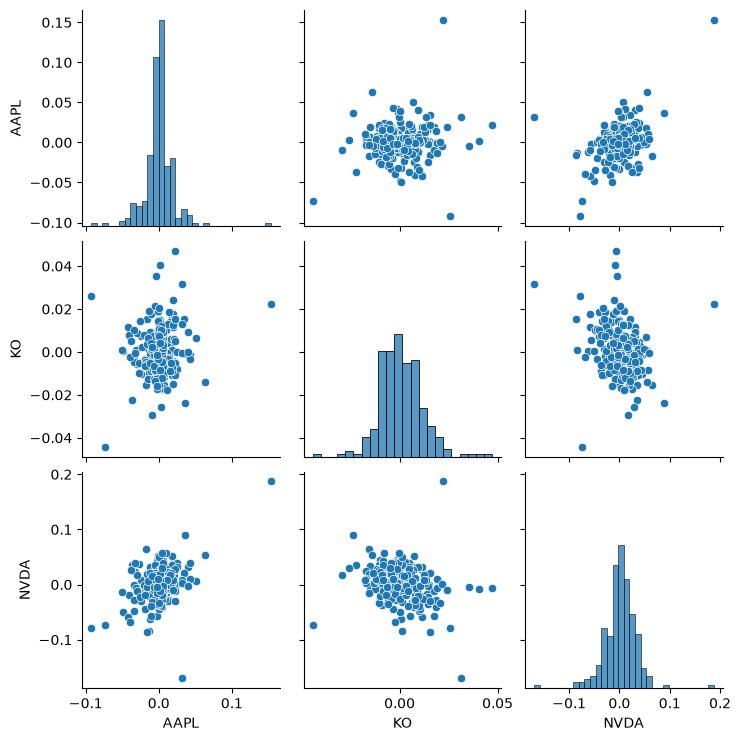

In [48]:
sns.pairplot(returns)
plt.show()

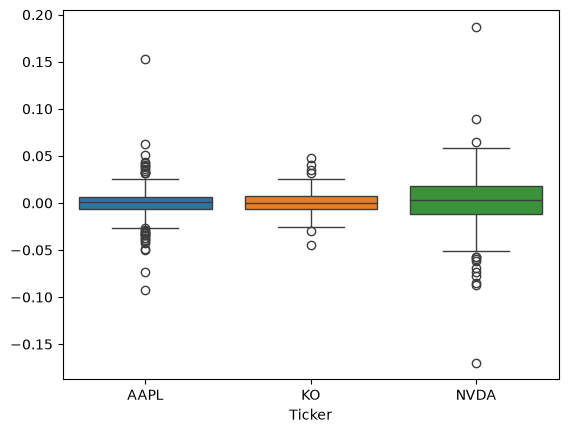

In [49]:
sns.boxplot(data=returns)
plt.show()

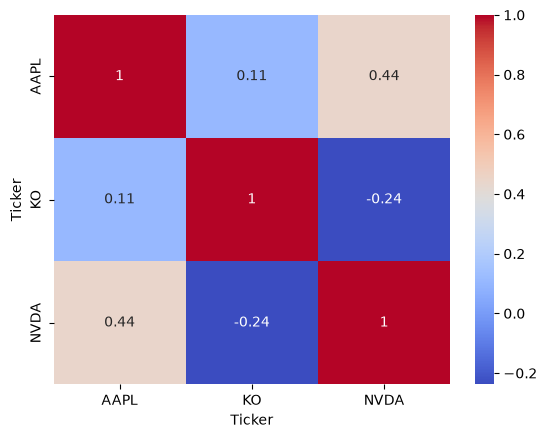

In [50]:
corr = returns.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()